<div align="center"> 

---

# **Cerebellum Mega Analysis — Site Confounding Sanity Checks**

</div>

---

In [1]:
addTaskCallback(function(...) {set.seed(42);TRUE})
options(warn=-1)
options(repr.plot.width=14, repr.plot.height=10)

1 
1

In [2]:
setwd("/mnt/g/Other computers/My Laptop/PhD/Psilantro/Enigma_cerebellum/Enigma_Cerebellum/")

## Load Packages

In [3]:
pacman::p_load(tidyverse, readxl, ggpubr, cowplot, gtsummary, ggthemes, scales,
               ggcorrplot, lme4, rstatix, janitor, patchwork, broom, emmeans,
               ggdist, rcartocolor, gt, gtExtras)

## Plot settings

In [4]:
pal_substances <- c("HC"   = alpha("#757575",1), "ALC" = alpha("#C93F4D",1),
                    "ATS"  = alpha("#EB8F33",1), "CANN"= alpha("#0B8755",1),
                    "COC"  = alpha("#3A5589",1), "NIC" = alpha("#764EA1",1),
                    "OPI"  = alpha("#06AED5",1))

dir.create("Statistics/Sanity_check", recursive = TRUE, showWarnings = FALSE)
dir.create("Figures/Sanity_check",   recursive = TRUE, showWarnings = FALSE)

## Load Data

In [5]:
load("Data/RData/Volumes_Cerebellum.RData")

# Prepare Acapulco volumes (mirrors 03-Permutation setup)
Acapulco_volumes <- Volumes_Cerebellum_Acapulco_Harmonized %>%
    filter(Substance != "OPI") %>%
    mutate(
        group     = factor(if_else(Substance == "HC", 0, 1), labels = c("HC", "User")),
        Substance = factor(Substance, levels = c("ALC","ATS","CANN","COC","NIC","HC"))
    ) %>%
    mutate(group = factor(group, levels = c("User","HC"))) %>%
    mutate(
        Database  = factor(Database),
        GM_Vol    = Total_Cerebel_Vol - Corpus.Medullare
    )

Acapulco_cerebellar_regions_names <- Acapulco_volumes %>%
    select(contains(c(".","_Vol"))) %>% colnames()

---
## **1. Site × Substance overlap**

Cross-tabulation and heatmap of subjects per scanner site and substance group.  
Sites where certain substance groups are entirely absent create partial aliasing between scanner and substance effects.

In [6]:
# Cross-tabulation: sites × substance groups
site_substance_table <- Acapulco_volumes %>%
    count(Database, Substance) %>%
    pivot_wider(names_from = Substance, values_from = n, values_fill = 0) %>%
    arrange(Database)

write_csv(site_substance_table, "Statistics/Sanity_check/site_by_substance_overlap.csv")
print(site_substance_table)

# A tibble: 55 × 7
   Database   ALC    HC   ATS  CANN   COC   NIC
   <fct>    <int> <int> <int> <int> <int> <int>
 1 ALC103     150     0     0     0     0     0
 2 ALC104     422     0     0     0     0     0
 3 ALC106       0   182     0     0     0     0
 4 ALC108       9    18     0     0     0     0
 5 ALC109      40     0     0     0     0     0
 6 ALC112      37    16     0     0     0     0
 7 ALC113      27    21     0     0     0     0
 8 ALC115      48   105     0     0     0     0
 9 ALC117      18    23     0     0     0     0
10 ALC118      33    18     0     0     0     0
# ℹ 45 more rows


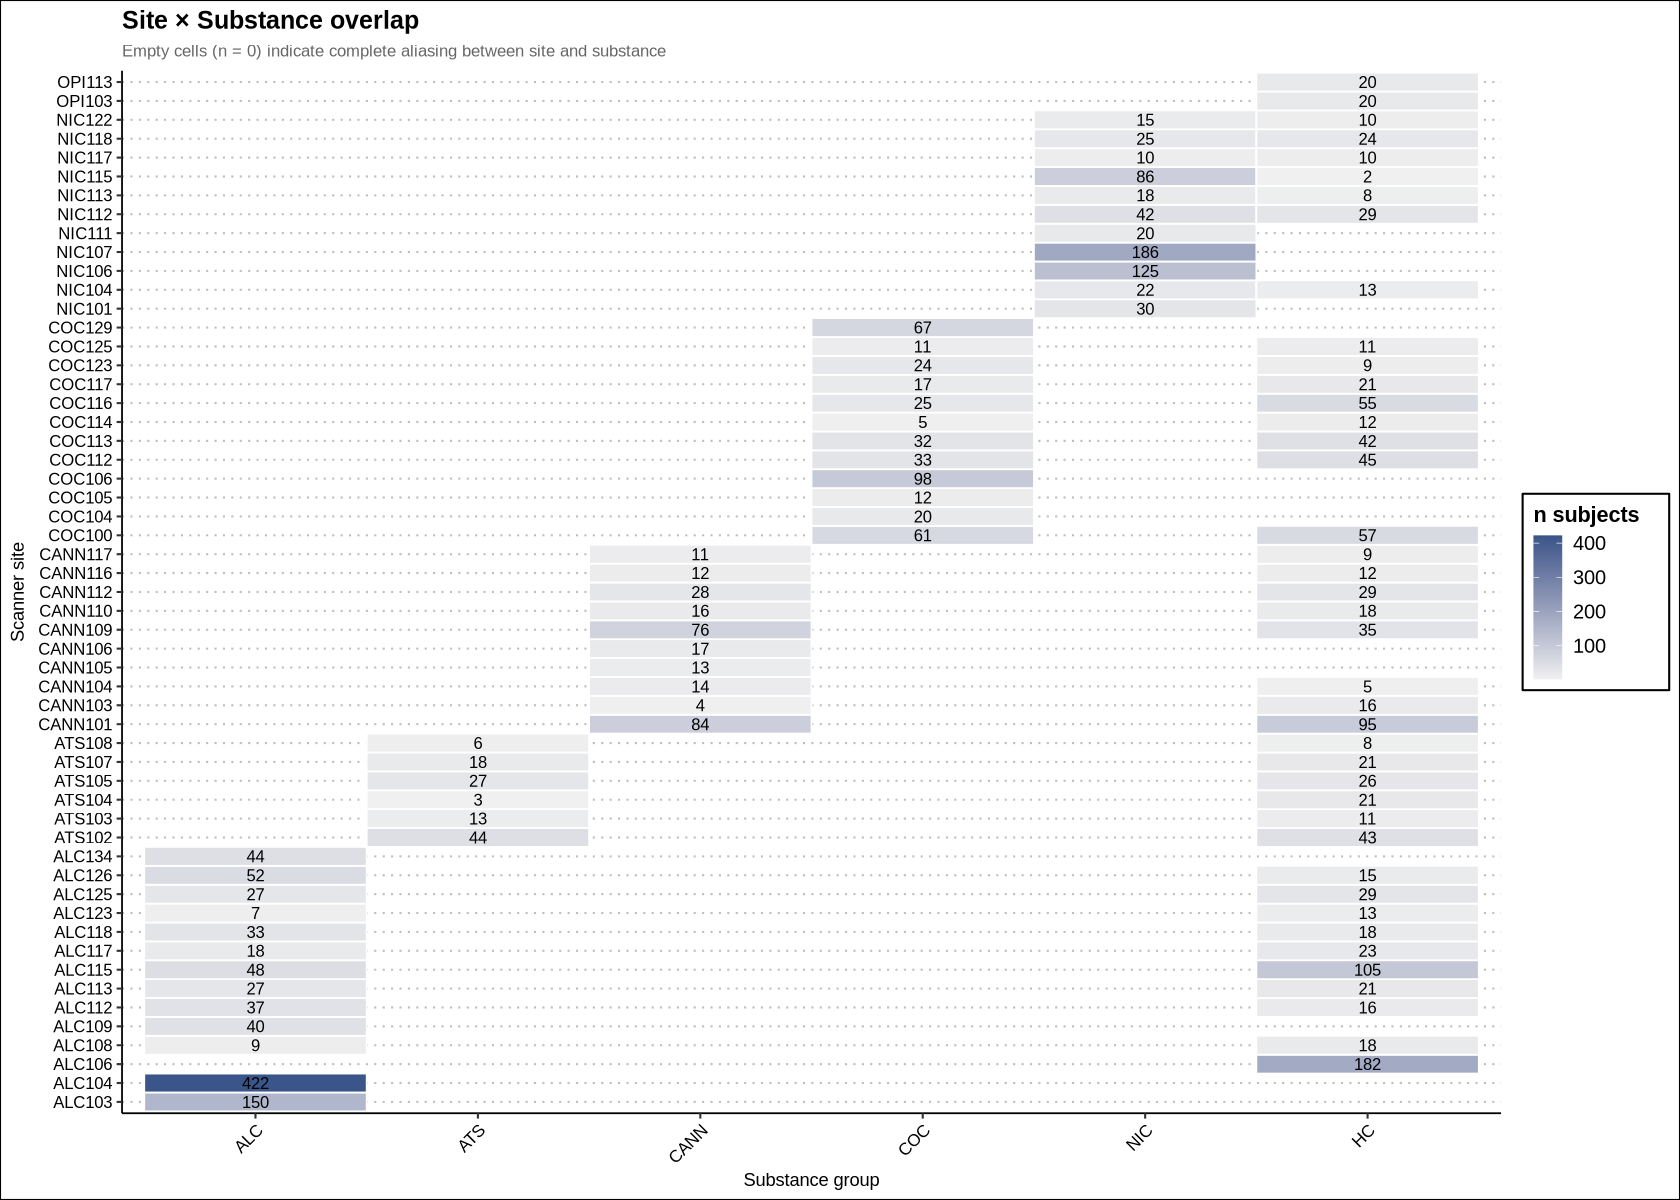

In [7]:
# Heatmap of site × substance counts
site_overlap_long <- Acapulco_volumes %>%
    count(Database, Substance)

plt_site_overlap <- site_overlap_long %>%
    ggplot(aes(x = Substance, y = Database, fill = n)) +
    geom_tile(color = "white", linewidth = 0.5) +
    geom_text(aes(label = n), size = 3.5, color = "black") +
    scale_fill_gradient(low = "#f0f0f0", high = "#3A5589", name = "n subjects") +
    labs(
        title    = "Site × Substance overlap",
        subtitle = "Empty cells (n = 0) indicate complete aliasing between site and substance",
        x = "Substance group", y = "Scanner site"
    ) +
    theme_clean(base_size = 13) +
    theme(axis.text.x = element_text(angle = 45, hjust = 1),
          plot.subtitle = element_text(size = 10, color = "grey40"))

ggsave(plot = plt_site_overlap,
       filename = "Figures/Sanity_check/site_substance_overlap_heatmap.png",
       width = 20, height = 24, units = "cm", bg = "white", dpi = 300)
plt_site_overlap

---
## **2. Within-site case-control linear models**

For each site that contributes at least 5 Users **and** 5 HCs, fit `volume ~ group` within that site only.  
This eliminates between-site confounding and tests whether substance effects are observable within any single site.

In [8]:
# Identify eligible sites
sites_with_both <- Acapulco_volumes %>%
    group_by(Database, group) %>%
    summarise(n = n(), .groups = "drop") %>%
    pivot_wider(names_from = group, values_from = n, values_fill = 0) %>%
    filter(User >= 5, HC >= 5) %>%
    pull(Database)

cat("Sites with \u2265 5 Users and \u2265 5 HCs:", length(sites_with_both), "\n")
print(as.character(sites_with_both))

Sites with ≥ 5 Users and ≥ 5 HCs: 35 
 [1] "ALC108"  "ALC112"  "ALC113"  "ALC115"  "ALC117"  "ALC118"  "ALC123" 
 [8] "ALC125"  "ALC126"  "ATS102"  "ATS103"  "ATS105"  "ATS107"  "ATS108" 
[15] "CANN101" "CANN104" "CANN109" "CANN110" "CANN112" "CANN116" "CANN117"
[22] "COC100"  "COC112"  "COC113"  "COC114"  "COC116"  "COC117"  "COC123" 
[29] "COC125"  "NIC104"  "NIC112"  "NIC113"  "NIC117"  "NIC118"  "NIC122" 


In [9]:
# Run within-site User vs HC linear model for all Acapulco cerebellar regions
within_site_results <- Acapulco_volumes %>%
    filter(Database %in% sites_with_both) %>%
    pivot_longer(names_to = "region", values_to = "volume",
                 all_of(Acapulco_cerebellar_regions_names)) %>%
    nest(data = -c(Database, region)) %>%
    mutate(test = map(data, ~ {
        m <- lm(volume ~ relevel(group, ref = "HC"), data = .x)
        broom::tidy(m, conf.int = TRUE) %>%
            filter(grepl("User", term)) %>%
            mutate(
                sigma       = sigma(m),
                effect.size = estimate / sigma(m),
                n_user      = sum(.x$group == "User"),
                n_hc        = sum(.x$group == "HC")
            )
    })) %>%
    unnest(test) %>%
    select(-data)

write_csv(within_site_results,
          "Statistics/Sanity_check/within_site_User_vs_HC.csv")
cat("Saved within-site results:", nrow(within_site_results), "rows\n")

Saved within-site results: 1050 rows


`height` was translated to `width`.
`height` was translated to `width`.


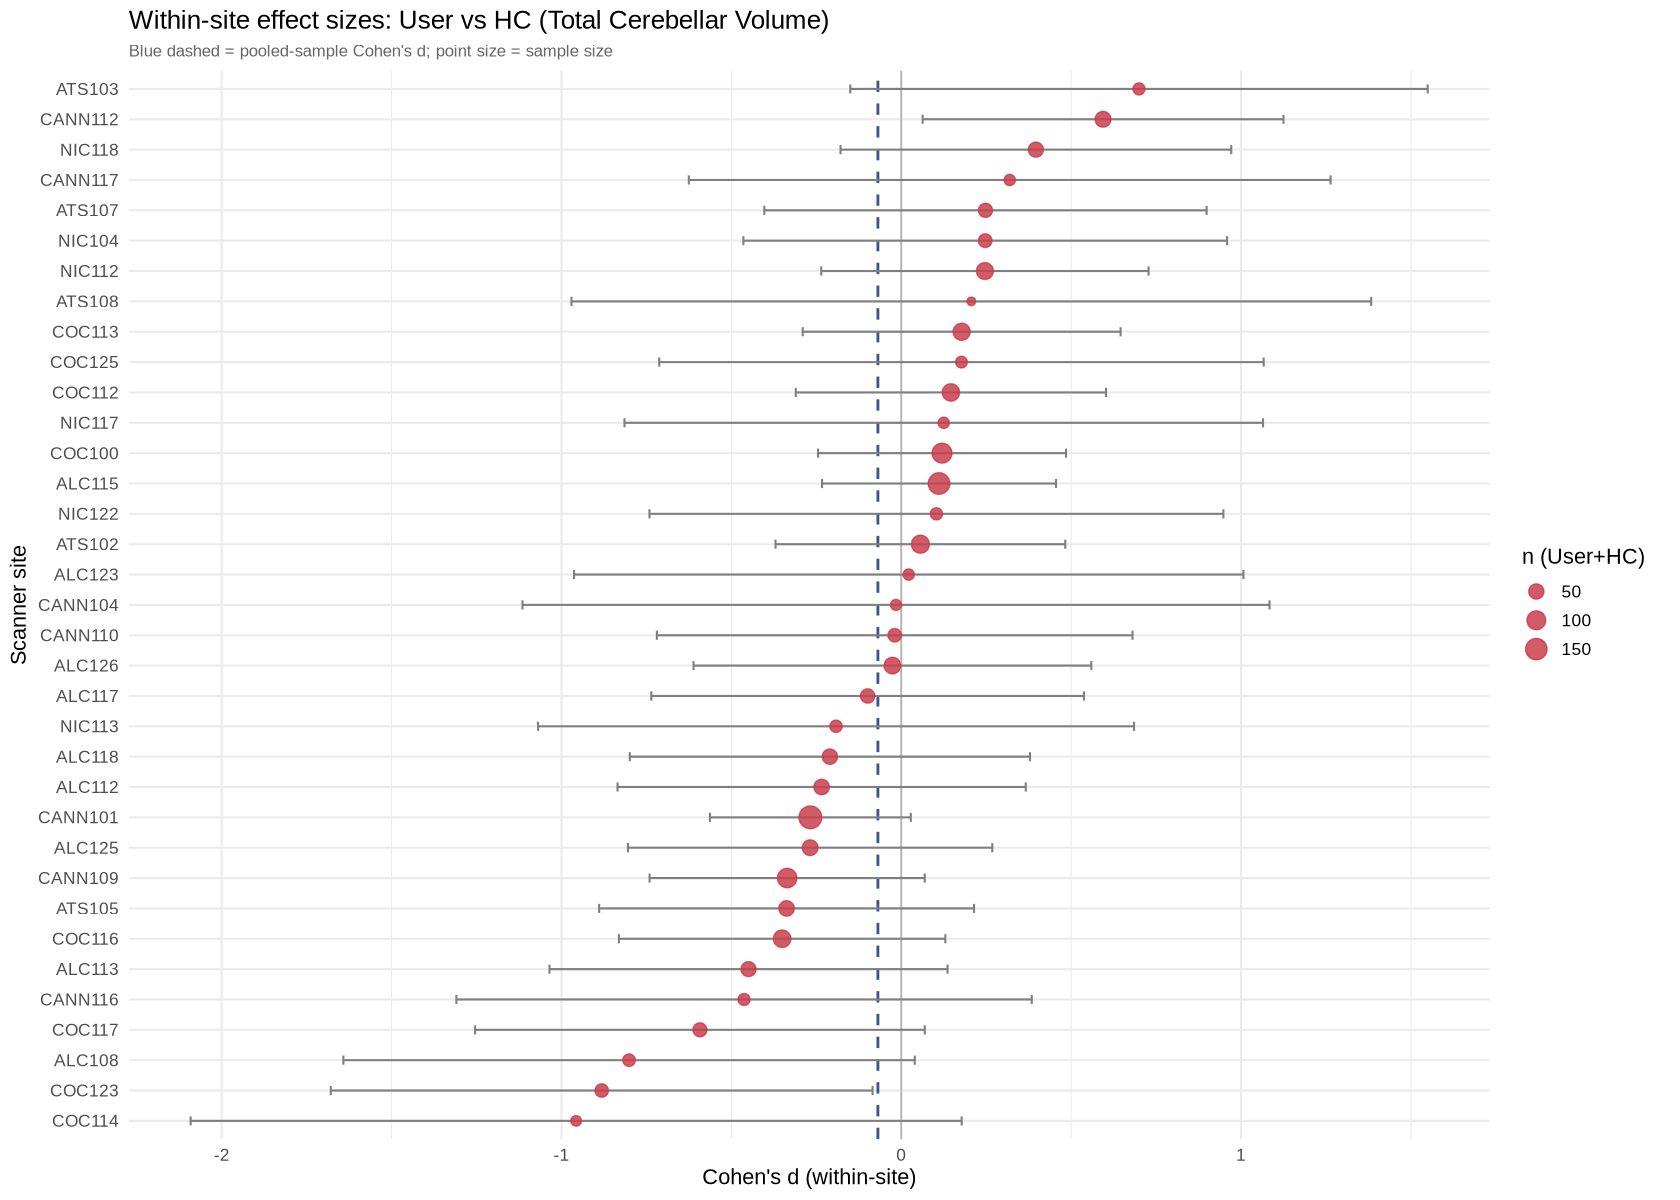

In [10]:
# Overall (pooled) effect for Total_Cerebel_Vol as reference line
overall_d_total <- {
    df <- Acapulco_volumes %>%
        filter(region_col <- TRUE) %>%
        mutate(group = relevel(group, ref = "HC"))
    m <- lm(Total_Cerebel_Vol ~ group, data = Acapulco_volumes %>%
                mutate(group = relevel(group, ref = "HC")))
    coef(m)["groupUser"] / sigma(m)
}

# Forest plot: within-site effect sizes for Total_Cerebel_Vol
plt_within_site <- within_site_results %>%
    filter(region == "Total_Cerebel_Vol") %>%
    mutate(Database = reorder(Database, effect.size)) %>%
    ggplot(aes(x = effect.size, y = Database)) +
    geom_vline(xintercept = overall_d_total, linetype = "dashed",
               color = "#3A5589", linewidth = 0.8) +
    geom_vline(xintercept = 0, color = "grey70", linewidth = 0.5) +
    geom_errorbarh(aes(xmin = conf.low / sigma, xmax = conf.high / sigma),
                   height = 0.3, color = "grey50") +
    geom_point(aes(size = n_user + n_hc), color = "#C93F4D", alpha = 0.85) +
    scale_size_continuous(name = "n (User+HC)", range = c(2, 6)) +
    labs(
        title    = "Within-site effect sizes: User vs HC (Total Cerebellar Volume)",
        subtitle = "Blue dashed = pooled-sample Cohen's d; point size = sample size",
        x        = "Cohen's d (within-site)", y = "Scanner site"
    ) +
    theme_minimal(base_size = 13) +
    theme(plot.subtitle = element_text(size = 10, color = "grey40"))

ggsave(plot = plt_within_site,
       filename = "Figures/Sanity_check/within_site_forest_TotalCerVol.png",
       width = 22, height = 16, units = "cm", bg = "white", dpi = 300)
plt_within_site

---
## **3. Leave-one-site-out (LOSO) effect sizes per substance**

For each substance, remove one site at a time and re-estimate Cohen's *d* for **Total Cerebellar Volume**.  
If results are stable across all LOSO iterations, no single site is driving the finding.

In [11]:
# LOSO function: for a given substance, remove each site and fit User vs HC
compute_loso_substance <- function(data, substance_name) {
    data_sub <- data %>%
        filter(Substance %in% c(substance_name, "HC")) %>%
        mutate(group = factor(
            if_else(Substance == "HC", "HC", "User"),
            levels = c("HC", "User")
        ))

    sites <- as.character(unique(data_sub$Database))

    map_dfr(sites, function(site) {
        df <- data_sub %>% filter(as.character(Database) != site)
        if (sum(df$group == "User") < 5 || sum(df$group == "HC") < 5) return(NULL)

        df %>%
            pivot_longer(
                names_to  = "region",
                values_to = "volume",
                all_of(Acapulco_cerebellar_regions_names)
            ) %>%
            nest(data = -region) %>%
            mutate(test = map(data, ~ {
                m <- lm(volume ~ relevel(group, ref = "HC"), data = .x)
                tibble(
                    effect.size = coef(m)[2] / sigma(m),
                    n_user      = sum(.x$group == "User"),
                    n_hc        = sum(.x$group == "HC")
                )
            })) %>%
            unnest(test) %>%
            select(-data) %>%
            mutate(substance = substance_name, site_removed = site)
    })
}

In [12]:
substances_to_test <- c("ALC", "ATS", "CANN", "COC", "NIC")
loso_fp <- "Statistics/Sanity_check/LOSO_effect_sizes.RData"

if (!file.exists(loso_fp)) {
    loso_results <- map_dfr(substances_to_test,
                            ~ compute_loso_substance(Acapulco_volumes, .x))
    save(loso_results, file = loso_fp)
} else {
    load(loso_fp)
}

write_csv(loso_results, "Statistics/Sanity_check/LOSO_effect_sizes.csv")
cat("LOSO results:", nrow(loso_results), "rows\n")

LOSO results: 6570 rows


In [13]:
# Overall (pooled) effect sizes for each substance (Total_Cerebel_Vol)
overall_effects <- map_dfr(substances_to_test, function(s) {
    df <- Acapulco_volumes %>%
        filter(Substance %in% c(s, "HC")) %>%
        mutate(group = factor(
            if_else(Substance == "HC", "HC", "User"),
            levels = c("HC", "User")
        ))
    m <- lm(Total_Cerebel_Vol ~ relevel(group, ref = "HC"), data = df)
    tibble(substance = s, effect_size_overall = coef(m)[2] / sigma(m))
})

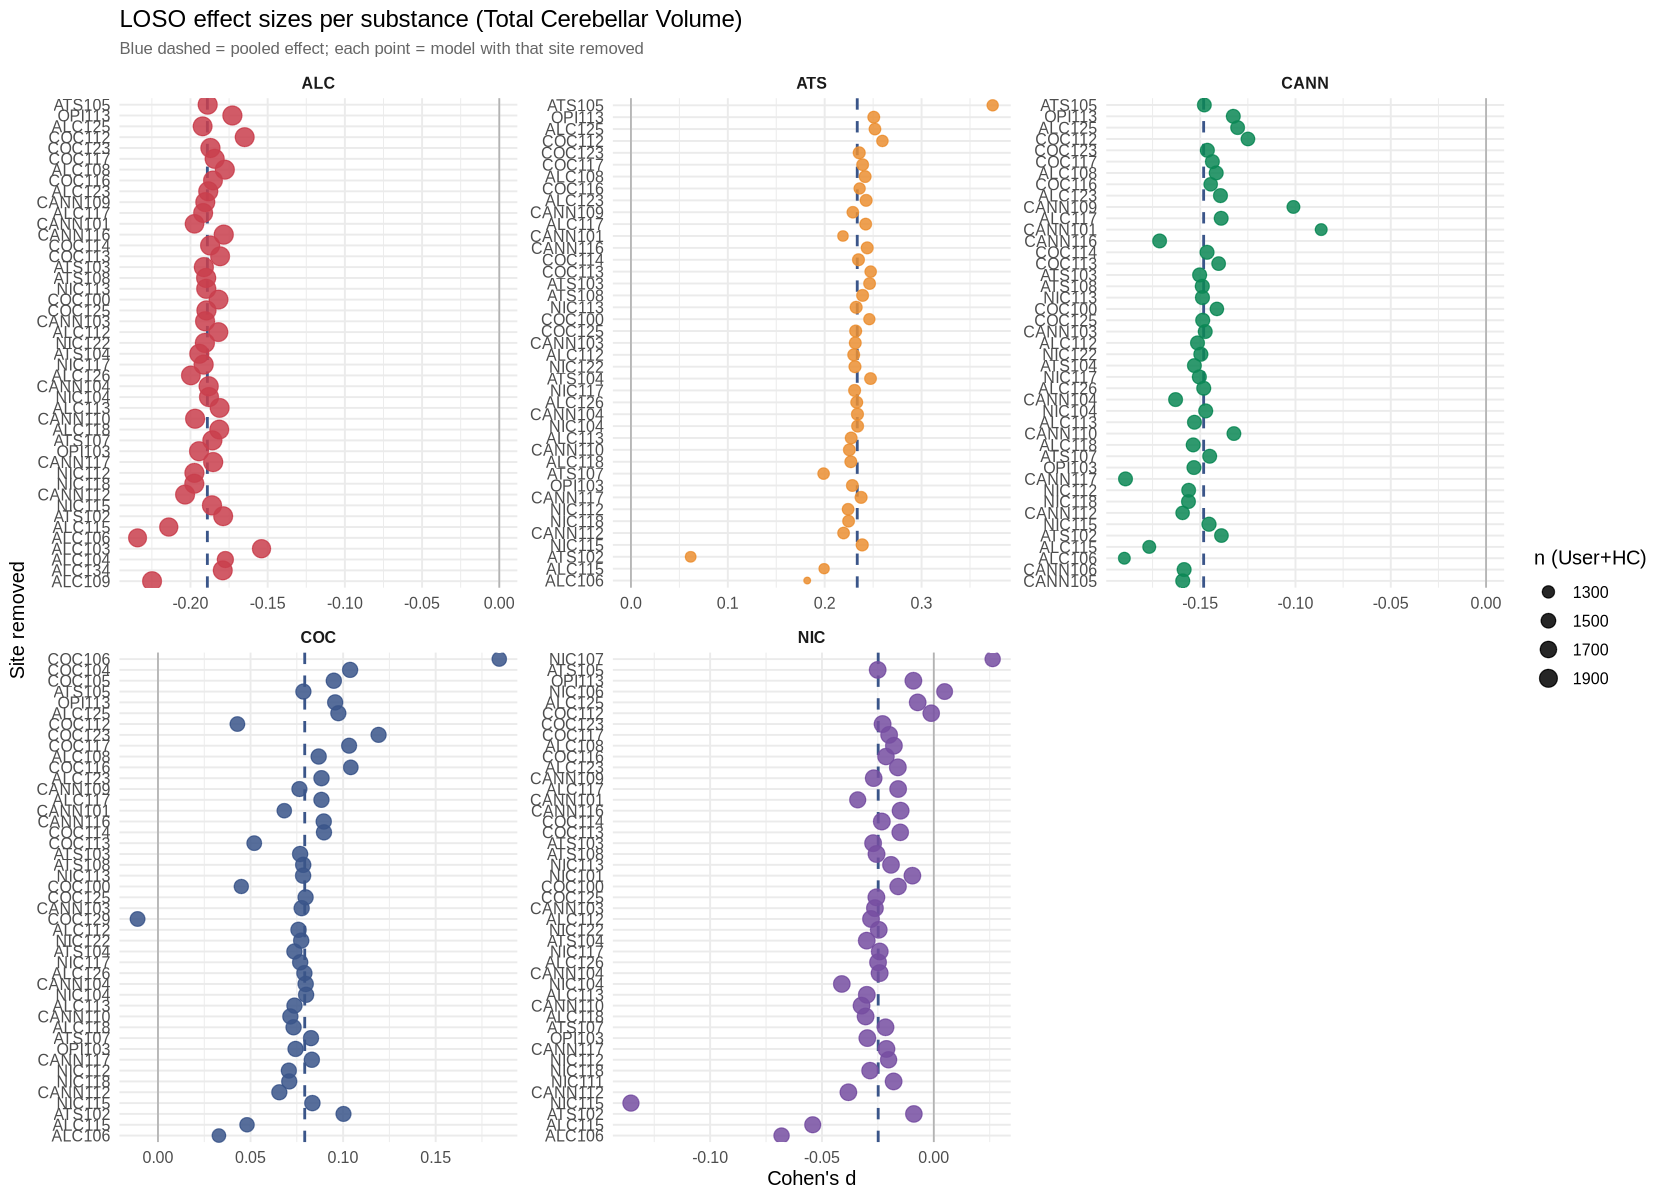

In [14]:
# LOSO forest plot: one panel per substance, Total Cerebellar Volume
plt_loso <- loso_results %>%
    filter(region == "Total_Cerebel_Vol") %>%
    left_join(overall_effects, by = "substance") %>%
    mutate(
        substance    = factor(substance, levels = substances_to_test),
        site_removed = reorder(site_removed, effect.size)
    ) %>%
    ggplot(aes(x = effect.size, y = site_removed)) +
    geom_vline(aes(xintercept = effect_size_overall),
               linetype = "dashed", color = "#3A5589", linewidth = 0.8) +
    geom_vline(xintercept = 0, color = "grey70", linewidth = 0.5) +
    geom_point(aes(size = n_user + n_hc, color = substance), alpha = 0.85) +
    scale_color_manual(values = pal_substances, guide = "none") +
    scale_size_continuous(name = "n (User+HC)", range = c(1.5, 5)) +
    facet_wrap(~substance, scales = "free", ncol = 3) +
    labs(
        title    = "LOSO effect sizes per substance (Total Cerebellar Volume)",
        subtitle = "Blue dashed = pooled effect; each point = model with that site removed",
        x        = "Cohen's d", y = "Site removed"
    ) +
    theme_minimal(base_size = 12) +
    theme(
        strip.text    = element_text(face = "bold"),
        plot.subtitle = element_text(size = 10, color = "grey40")
    )

ggsave(plot = plt_loso,
       filename = "Figures/Sanity_check/LOSO_per_substance_TotalCerVol.png",
       width = 32, height = 22, units = "cm", bg = "white", dpi = 300)
plt_loso

In [15]:
# Summary table: SD of LOSO effect sizes per substance (robustness metric)
loso_summary <- loso_results %>%
    filter(region == "Total_Cerebel_Vol") %>%
    group_by(substance) %>%
    summarise(
        n_loso_iter    = n(),
        mean_d         = round(mean(effect.size, na.rm = TRUE), 3),
        sd_d           = round(sd(effect.size,   na.rm = TRUE), 3),
        min_d          = round(min(effect.size,  na.rm = TRUE), 3),
        max_d          = round(max(effect.size,  na.rm = TRUE), 3),
        .groups = "drop"
    ) %>%
    left_join(overall_effects, by = "substance")

write_csv(loso_summary, "Statistics/Sanity_check/LOSO_summary_TotalCerVol.csv")
print(loso_summary)

# A tibble: 5 × 7
  substance n_loso_iter mean_d  sd_d  min_d  max_d effect_size_overall
  <chr>           <int>  <dbl> <dbl>  <dbl>  <dbl>               <dbl>
1 ALC                45 -0.189 0.013 -0.234 -0.154             -0.189 
2 ATS                41  0.232 0.038  0.062  0.373              0.234 
3 CANN               43 -0.148 0.018 -0.19  -0.087             -0.148 
4 COC                45  0.079 0.027 -0.011  0.184              0.0793
5 NIC                45 -0.025 0.022 -0.135  0.026             -0.0249


---

# **Section 9: Summary Statistics — Harmonization Variants Comparison**

Compare sample sizes, residual properties, and data quality across three harmonization approaches:
- **CA** (Covariate-Adjusted): Stratified residualization + ComBat
- **CC** (Complete Cases): Age/Sex observed, no imputation
- **AI** (Alternative Imputation): Age/Sex imputed (Substance + Site only)



In [16]:
# Load harmonized datasets for all three approaches
cat("Loading harmonized datasets...\n")

# Load CA (Covariate-Adjusted) variants from CSV (more reliable than RData naming issues)
CA_acap <- read_csv("Data/Volumes_Cerebellum_Acapulco_Harmonized_CA.csv", show_col_types = FALSE)
CA_mdtb <- read_csv("Data/Volumes_Cerebellum_MDTB_Harmonized_CA.csv", show_col_types = FALSE)
CA_dk <- read_csv("Data/Volumes_Cerebral_DK_Harmonized_CA.csv", show_col_types = FALSE)

# Load CC and AI variants from sanity check RData
load("Data/RData/Sanity_check/Volumes_Cerebellum_Sanity_check.RData")

CC_acap <- Volumes_Cerebellum_Acapulco_Harmonized_CC
CC_mdtb <- Volumes_Cerebellum_MDTB_Harmonized_CC
CC_dk <- Volumes_Cerebral_DK_Harmonized_CC

AI_acap <- Volumes_Cerebellum_Acapulco_Harmonized_AI
AI_mdtb <- Volumes_Cerebellum_MDTB_Harmonized_AI
AI_dk <- Volumes_Cerebral_DK_Harmonized_AI

cat("✓ All datasets loaded\n")
cat("  CA - Acapulco: ", nrow(CA_acap), " subjects\n")
cat("  CA - MDTB:     ", nrow(CA_mdtb), " subjects\n")
cat("  CA - DK:       ", nrow(CA_dk), " subjects\n")
cat("  CC - Acapulco: ", nrow(CC_acap), " subjects\n")
cat("  CC - MDTB:     ", nrow(CC_mdtb), " subjects\n")
cat("  CC - DK:       ", nrow(CC_dk), " subjects\n")
cat("  AI - Acapulco: ", nrow(AI_acap), " subjects\n")
cat("  AI - MDTB:     ", nrow(AI_mdtb), " subjects\n")
cat("  AI - DK:       ", nrow(AI_dk), " subjects\n")


Loading harmonized datasets...


✓ All datasets loaded
  CA - Acapulco:  2612  subjects
  CA - MDTB:      1685  subjects
  CA - DK:        1627  subjects
  CC - Acapulco:  2991  subjects
  CC - MDTB:      2991  subjects
  CC - DK:        2903  subjects
  AI - Acapulco:  3519  subjects
  AI - MDTB:      3519  subjects
  AI - DK:        3373  subjects


In [17]:
# ====== 9.1: SAMPLE SIZES ACROSS VARIANTS ======

cat("\n========== SUMMARY STATISTICS: SAMPLE SIZES ==========\n")

summary_n <- tibble(
    Atlas = c("Acapulco", "MDTB", "DK",
              "Acapulco", "MDTB", "DK",
              "Acapulco", "MDTB", "DK"),
    Variant = c(rep("CA (Covariate-Adjusted)", 3),
                rep("CC (Complete Cases)", 3),
                rep("AI (Alternative Imputation)", 3)),
    `Sample Size` = c(nrow(CA_acap), nrow(CA_mdtb), nrow(CA_dk),
                      nrow(CC_acap), nrow(CC_mdtb), nrow(CC_dk),
                      nrow(AI_acap), nrow(AI_mdtb), nrow(AI_dk)),
    `Databases` = c(CA_acap$Database %>% n_distinct(),
                    CA_mdtb$Database %>% n_distinct(),
                    CA_dk$Database %>% n_distinct(),
                    CC_acap$Database %>% n_distinct(),
                    CC_mdtb$Database %>% n_distinct(),
                    CC_dk$Database %>% n_distinct(),
                    AI_acap$Database %>% n_distinct(),
                    AI_mdtb$Database %>% n_distinct(),
                    AI_dk$Database %>% n_distinct())
)

print(summary_n)

cat("\n✓ Sample sizes summary saved\n")



========== SUMMARY STATISTICS: SAMPLE SIZES ==========
# A tibble: 9 × 4
  Atlas    Variant                     `Sample Size` Databases
  <chr>    <chr>                               <int>     <int>
1 Acapulco CA (Covariate-Adjusted)              2612        52
2 MDTB     CA (Covariate-Adjusted)              1685        50
3 DK       CA (Covariate-Adjusted)              1627        50
4 Acapulco CC (Complete Cases)                  2991        54
5 MDTB     CC (Complete Cases)                  2991        54
6 DK       CC (Complete Cases)                  2903        54
7 Acapulco AI (Alternative Imputation)          3519        55
8 MDTB     AI (Alternative Imputation)          3519        55
9 DK       AI (Alternative Imputation)          3373        55

✓ Sample sizes summary saved


In [18]:
# ====== 9.2: SAMPLE BREAKDOWN BY SUBSTANCE (CA VARIANT) ======

cat("\n========== SUBSTANCE BREAKDOWN (CA VARIANT) ==========\n")

substance_breakdown_acap <- CA_acap %>%
    group_by(Substance) %>%
    summarise(n = n(), .groups = "drop") %>%
    rename(Acapulco = n)

substance_breakdown_mdtb <- CA_mdtb %>%
    group_by(Substance) %>%
    summarise(n = n(), .groups = "drop") %>%
    rename(MDTB = n)

substance_breakdown_dk <- CA_dk %>%
    group_by(Substance) %>%
    summarise(n = n(), .groups = "drop") %>%
    rename(DK = n)

substance_breakdown <- substance_breakdown_acap %>%
    left_join(substance_breakdown_mdtb, by = "Substance") %>%
    left_join(substance_breakdown_dk, by = "Substance") %>%
    mutate(across(-Substance, ~replace_na(., 0)))

print(substance_breakdown)

cat("\n✓ Substance breakdown saved\n")



========== SUBSTANCE BREAKDOWN (CA VARIANT) ==========
# A tibble: 7 × 4
  Substance Acapulco  MDTB    DK
  <chr>        <int> <int> <int>
1 ALC            376   394   371
2 ATS            111   111   111
3 CANN           259   224   259
4 COC            361   393   361
5 HC             977     0     0
6 NIC            473   505   470
7 OPI             55    58    55

✓ Substance breakdown saved


In [19]:
# ====== 9.3: COMPARISON ACROSS VARIANTS (BY SUBSTANCE) ======

cat("\n========== ACAPULCO: SAMPLE SIZES BY VARIANT & SUBSTANCE ==========\n")

acap_variants <- bind_rows(
    CA_acap %>% mutate(Variant = "CA") %>% select(Substance, Variant),
    CC_acap %>% mutate(Variant = "CC") %>% select(Substance, Variant),
    AI_acap %>% mutate(Variant = "AI") %>% select(Substance, Variant)
) %>%
    group_by(Variant, Substance) %>%
    summarise(n = n(), .groups = "drop") %>%
    pivot_wider(names_from = Substance, values_from = n, values_fill = 0)

print(acap_variants)

cat("\n========== MDTB: SAMPLE SIZES BY VARIANT & SUBSTANCE ==========\n")

mdtb_variants <- bind_rows(
    CA_mdtb %>% mutate(Variant = "CA") %>% select(Substance, Variant),
    CC_mdtb %>% mutate(Variant = "CC") %>% select(Substance, Variant),
    AI_mdtb %>% mutate(Variant = "AI") %>% select(Substance, Variant)
) %>%
    group_by(Variant, Substance) %>%
    summarise(n = n(), .groups = "drop") %>%
    pivot_wider(names_from = Substance, values_from = n, values_fill = 0)

print(mdtb_variants)

cat("\n========== DK (CEREBRAL): SAMPLE SIZES BY VARIANT & SUBSTANCE ==========\n")

dk_variants <- bind_rows(
    CA_dk %>% mutate(Variant = "CA") %>% select(Substance, Variant),
    CC_dk %>% mutate(Variant = "CC") %>% select(Substance, Variant),
    AI_dk %>% mutate(Variant = "AI") %>% select(Substance, Variant)
) %>%
    group_by(Variant, Substance) %>%
    summarise(n = n(), .groups = "drop") %>%
    pivot_wider(names_from = Substance, values_from = n, values_fill = 0)

print(dk_variants)



========== ACAPULCO: SAMPLE SIZES BY VARIANT & SUBSTANCE ==========
# A tibble: 3 × 8
  Variant   ALC   ATS  CANN   COC    HC   NIC   OPI
  <chr>   <int> <int> <int> <int> <int> <int> <int>
1 AI        914   111   275   405  1177   579    58
2 CA        376   111   259   361   977   473    55
3 CC        486   111   275   393  1167   501    58

========== MDTB: SAMPLE SIZES BY VARIANT & SUBSTANCE ==========
# A tibble: 3 × 8
  Variant   ALC   ATS  CANN   COC    HC   NIC   OPI
  <chr>   <int> <int> <int> <int> <int> <int> <int>
1 AI        914   111   275   405  1177   579    58
2 CA        394   111   224   393     0   505    58
3 CC        486   111   275   393  1167   501    58

========== DK (CEREBRAL): SAMPLE SIZES BY VARIANT & SUBSTANCE ==========
# A tibble: 3 × 8
  Variant   ALC   ATS  CANN   COC    HC   NIC   OPI
  <chr>   <int> <int> <int> <int> <int> <int> <int>
1 AI        847   111   274   373  1183   530    55
2 CA        371   111   259   361     0   470    55
3 CC      

In [20]:
# ====== 9.4: VOLUME DISTRIBUTION QUALITY CHECKS ======

cat("\n========== VOLUME QUALITY METRICS (CA VARIANT) ==========\n")

# Extract volume columns for each atlas
vol_cols_acap <- names(CA_acap) %>% .[grepl("\\.", .)]  # ROI columns contain "."
vol_cols_mdtb <- names(CA_mdtb) %>% .[grepl("region", .)]
vol_cols_dk <- names(CA_dk) %>% .[grepl("lh_|rh_", .)]

# Quality check: mean, SD, range for Acapulco
quality_acap <- CA_acap %>%
    select(all_of(vol_cols_acap)) %>%
    summarise(across(everything(),
                     list(Mean = ~mean(., na.rm=TRUE),
                          SD = ~sd(., na.rm=TRUE),
                          Min = ~min(., na.rm=TRUE),
                          Max = ~max(., na.rm=TRUE)))) %>%
    pivot_longer(everything(),
                 names_to = c("ROI", "Metric"),
                 names_sep = "_") %>%
    pivot_wider(names_from = Metric, values_from = value)

cat("Acapulco - First 5 ROIs:\n")
print(head(quality_acap, 5))

# Quality check: MDTB
quality_mdtb <- CA_mdtb %>%
    select(all_of(vol_cols_mdtb)) %>%
    summarise(across(everything(),
                     list(Mean = ~mean(., na.rm=TRUE),
                          SD = ~sd(., na.rm=TRUE),
                          Min = ~min(., na.rm=TRUE),
                          Max = ~max(., na.rm=TRUE)))) %>%
    pivot_longer(everything(),
                 names_to = c("Region", "Metric"),
                 names_sep = "_") %>%
    pivot_wider(names_from = Metric, values_from = value)

cat("\nMDTB - First 5 regions:\n")
print(head(quality_mdtb, 5))

# Quality check: DK
quality_dk <- CA_dk %>%
    select(all_of(vol_cols_dk)) %>%
    summarise(across(everything(),
                     list(Mean = ~mean(., na.rm=TRUE),
                          SD = ~sd(., na.rm=TRUE),
                          Min = ~min(., na.rm=TRUE),
                          Max = ~max(., na.rm=TRUE)))) %>%
    pivot_longer(everything(),
                 names_to = c("Region", "Metric"),
                 names_sep = "_") %>%
    pivot_wider(names_from = Metric, values_from = value)

cat("\nDK - First 5 regions:\n")
print(head(quality_dk, 5))

cat("\n✓ Quality checks complete\n")



========== VOLUME QUALITY METRICS (CA VARIANT) ==========
Acapulco - First 5 ROIs:
# A tibble: 5 × 5
  ROI                      Mean       SD       Min      Max
  <chr>                   <dbl>    <dbl>     <dbl>    <dbl>
1 Corpus.Medullare  0.00000243  0.00174  -0.00988  0.0142  
2 Left.Crus.I      -0.0000226   0.00169  -0.00564  0.00843 
3 Left.Crus.II     -0.00000715  0.00115  -0.00483  0.00555 
4 Left.I.III       -0.00000109  0.000152 -0.000454 0.000825
5 Left.IV          -0.000000853 0.000410 -0.00134  0.00139 

MDTB - First 5 regions:
# A tibble: 1 × 11
  Region `1`       `2`       `3`       `4`   `5`   `6`   `7`   `8`   `9`   `10` 
  <chr>  <list>    <list>    <list>    <lis> <lis> <lis> <lis> <lis> <lis> <lis>
1 region <dbl [4]> <dbl [4]> <dbl [4]> <dbl> <dbl> <dbl> <dbl> <dbl> <dbl> <dbl>

DK - First 5 regions:
# A tibble: 2 × 35
  Region bankssts  caudalanteriorcingulate caudalmiddlefrontal cuneus entorhinal
  <chr>  <list>    <list>                  <list>              <list

In [21]:
# ====== 9.5: INTER-VOLUME CORRELATIONS (CA VARIANT) ======

cat("\n========== VOLUME CORRELATIONS (CA VARIANT) ==========\n")

# Acapulco correlations
cor_acap <- CA_acap %>%
    select(all_of(vol_cols_acap)) %>%
    cor(use = "complete.obs") %>%
    as.numeric() %>%
    .[. != 1]  # Remove diagonal

cat("Acapulco ROIs - Mean inter-volume correlation: ",
    round(mean(cor_acap, na.rm=TRUE), 3), "\n")
cat("  Min: ", round(min(cor_acap, na.rm=TRUE), 3), " | ",
    "Max: ", round(max(cor_acap, na.rm=TRUE), 3), "\n")

# MDTB correlations
cor_mdtb <- CA_mdtb %>%
    select(all_of(vol_cols_mdtb)) %>%
    cor(use = "complete.obs") %>%
    as.numeric() %>%
    .[. != 1]

cat("\nMDTB regions - Mean inter-volume correlation: ",
    round(mean(cor_mdtb, na.rm=TRUE), 3), "\n")
cat("  Min: ", round(min(cor_mdtb, na.rm=TRUE), 3), " | ",
    "Max: ", round(max(cor_mdtb, na.rm=TRUE), 3), "\n")

# DK correlations
cor_dk <- CA_dk %>%
    select(all_of(vol_cols_dk)) %>%
    cor(use = "complete.obs") %>%
    as.numeric() %>%
    .[. != 1]

cat("\nDK regions - Mean inter-volume correlation: ",
    round(mean(cor_dk, na.rm=TRUE), 3), "\n")
cat("  Min: ", round(min(cor_dk, na.rm=TRUE), 3), " | ",
    "Max: ", round(max(cor_dk, na.rm=TRUE), 3), "\n")

cat("\n✓ Correlation analysis complete\n")



========== VOLUME CORRELATIONS (CA VARIANT) ==========
Acapulco ROIs - Mean inter-volume correlation:  0.324 
  Min:  0.049  |  Max:  0.875 

MDTB regions - Mean inter-volume correlation:  0.268 
  Min:  -0.632  |  Max:  0.931 

DK regions - Mean inter-volume correlation:  0.323 
  Min:  0.064  |  Max:  0.817 

✓ Correlation analysis complete



========== CREATING VISUALIZATIONS ==========


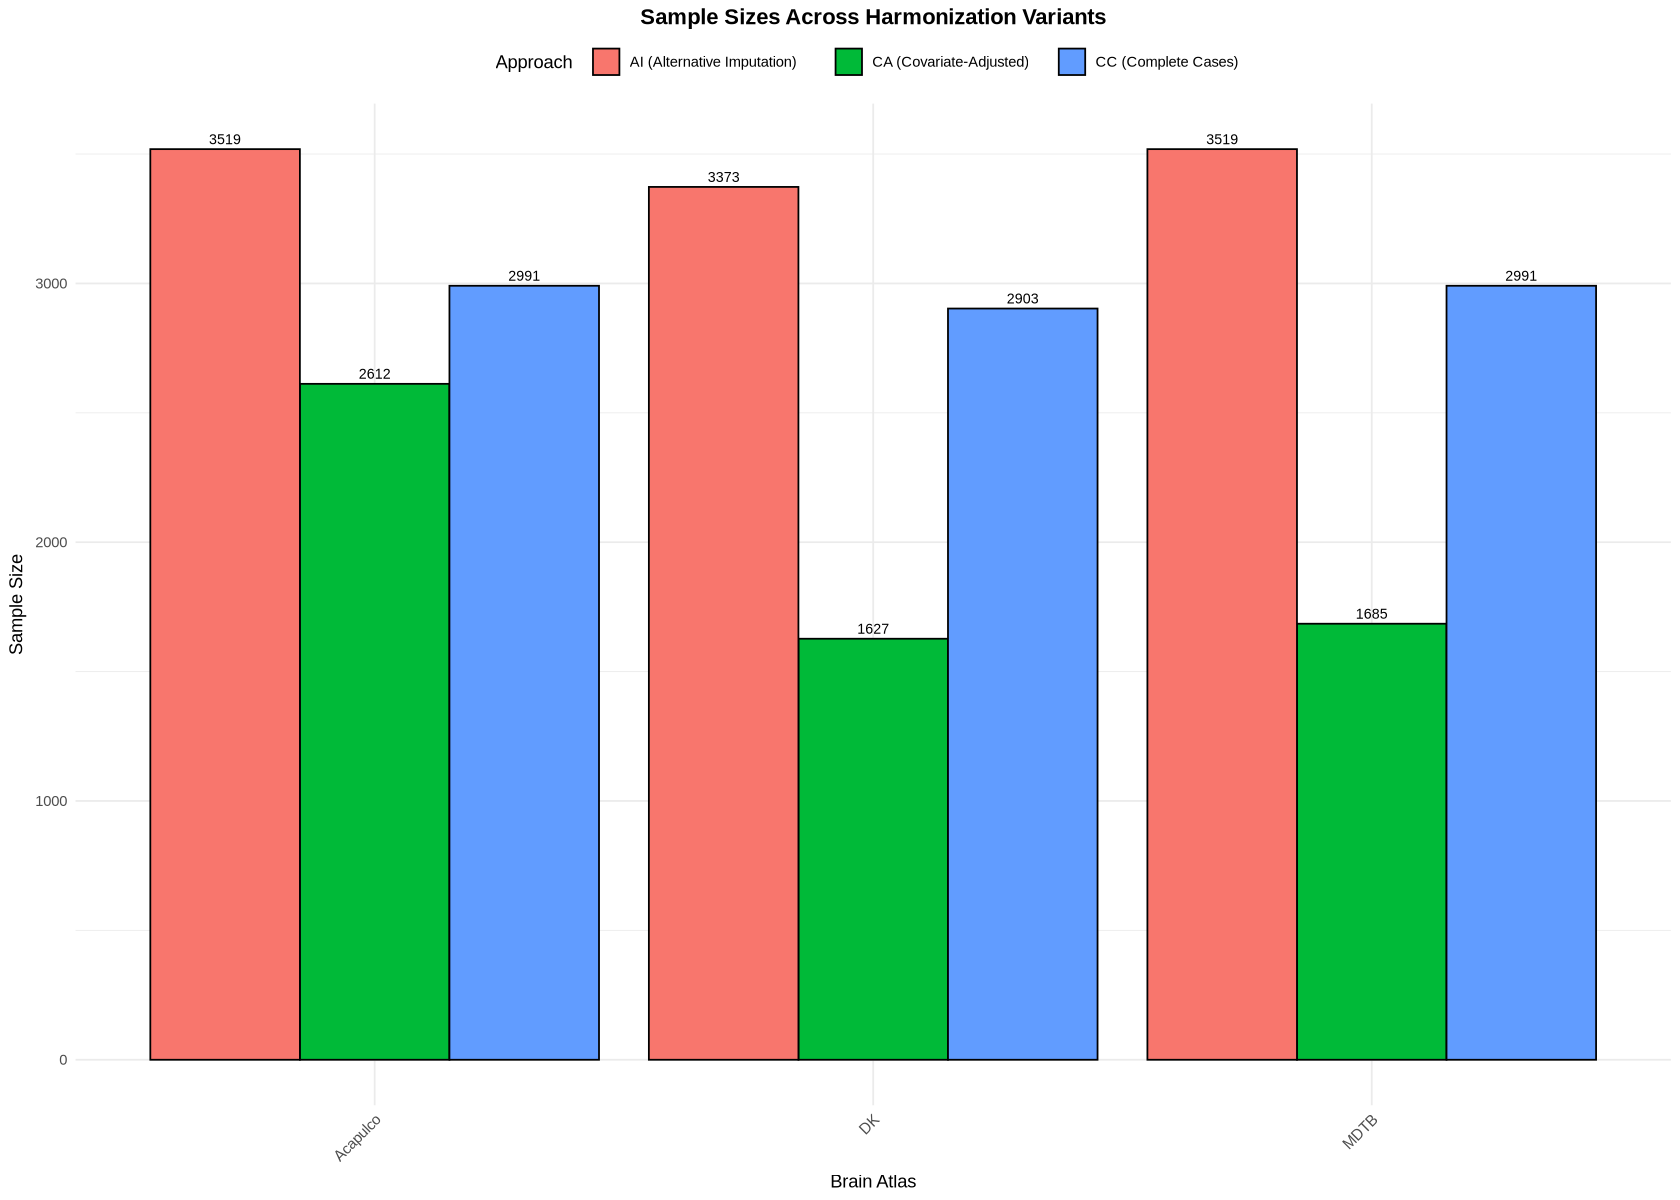

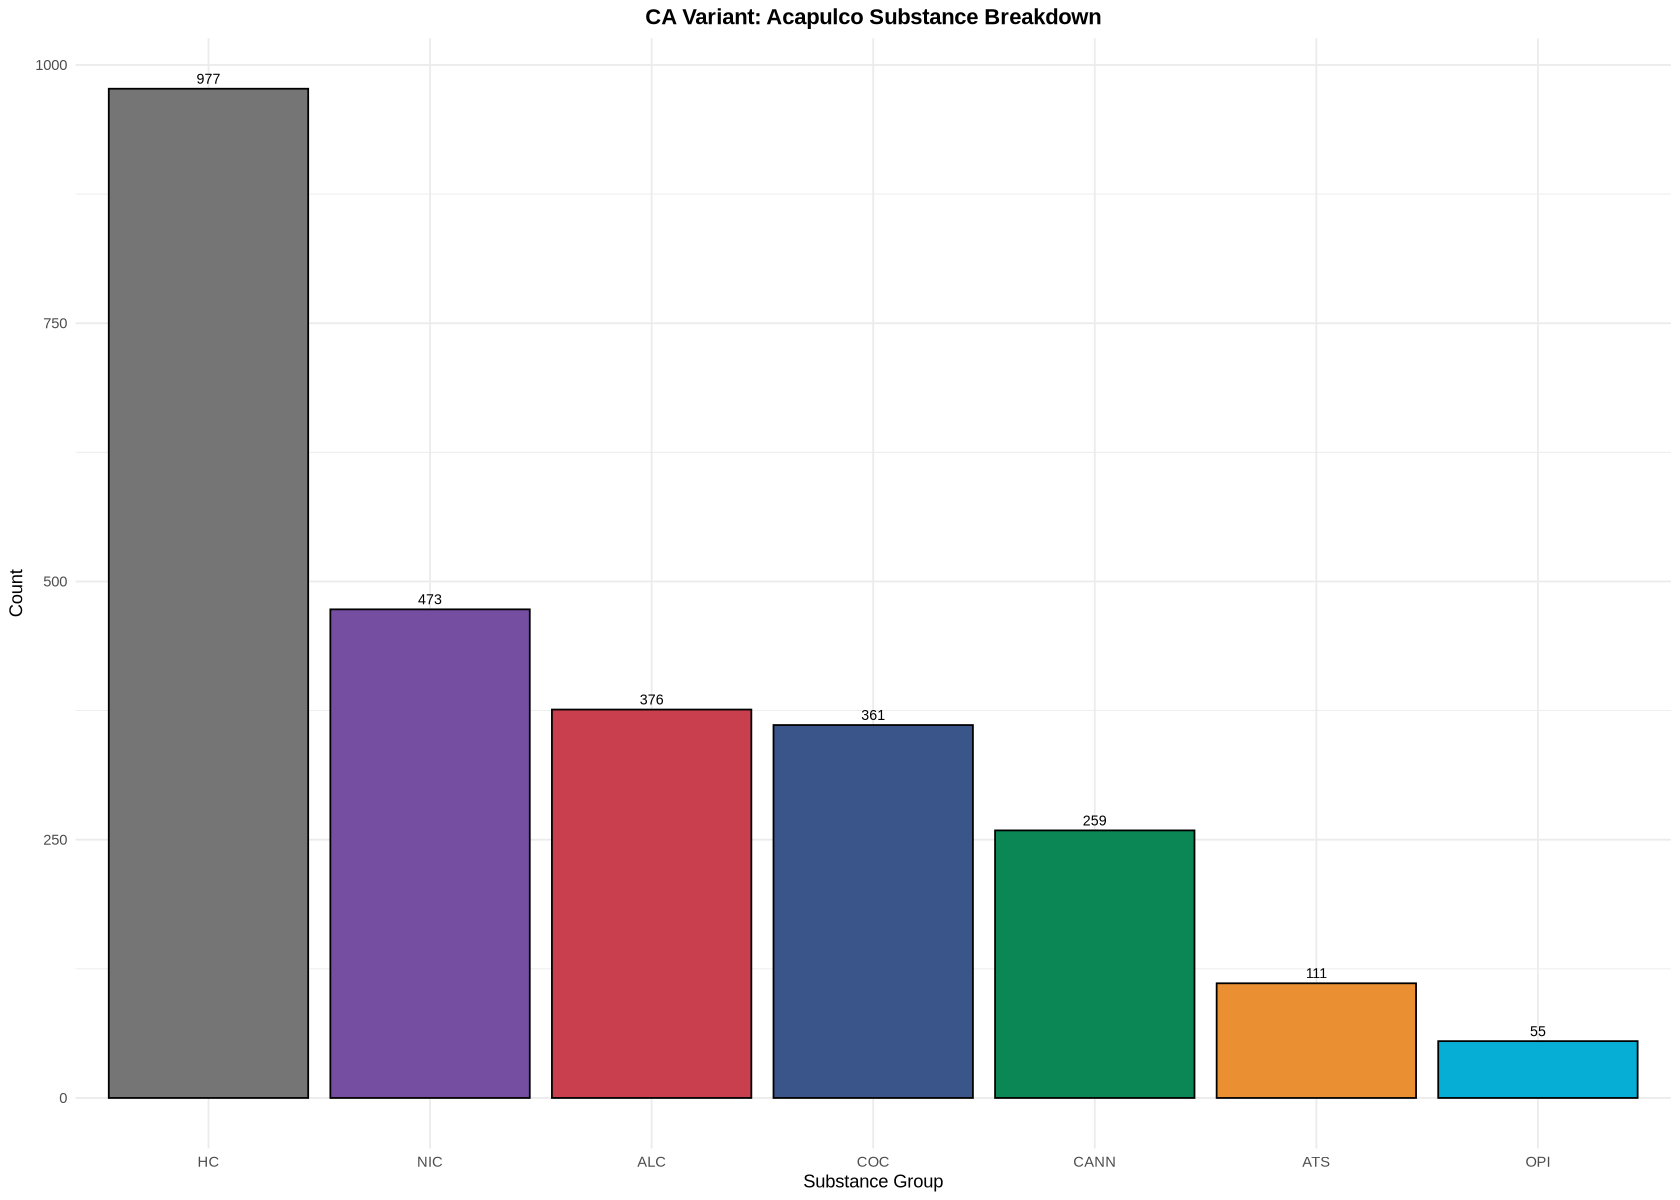

✓ Visualizations created


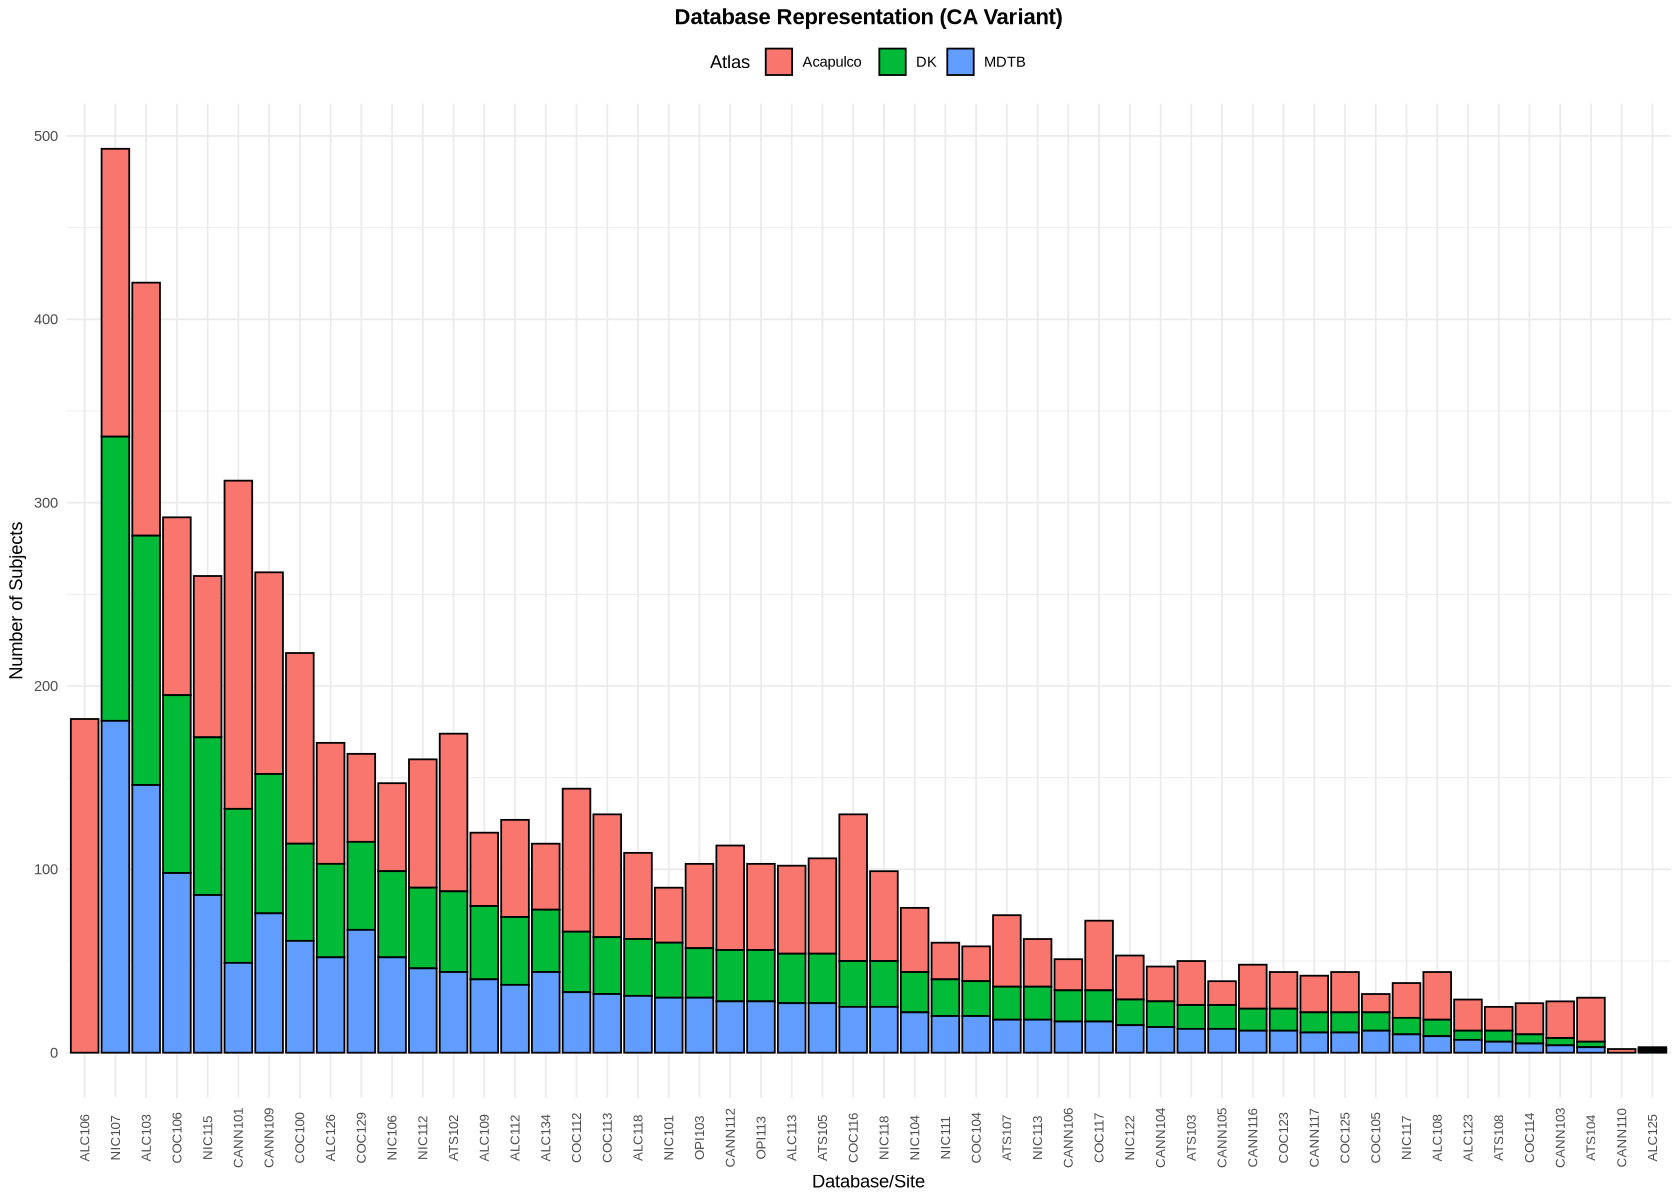

In [22]:
# ====== 9.6: VISUALIZATIONS - SAMPLE SIZE COMPARISON ======

cat("\n========== CREATING VISUALIZATIONS ==========\n")

# Plot 1: Sample sizes by atlas and variant
p1 <- summary_n %>%
    ggplot(aes(x = Atlas, y = `Sample Size`, fill = Variant)) +
    geom_col(position = "dodge", color = "black", size = 0.4) +
    labs(title = "Sample Sizes Across Harmonization Variants",
         x = "Brain Atlas", y = "Sample Size",
         fill = "Approach") +
    theme_minimal() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1),
          plot.title = element_text(hjust = 0.5, face = "bold"),
          legend.position = "top") +
    geom_text(aes(label = `Sample Size`), position = position_dodge(width = 0.9),
              vjust = -0.5, size = 3)

print(p1)

# Plot 2: Substance breakdown for CA Acapulco
p2 <- CA_acap %>%
    group_by(Substance) %>%
    summarise(n = n(), .groups = "drop") %>%
    mutate(Substance = fct_reorder(Substance, n, .desc = TRUE)) %>%
    ggplot(aes(x = Substance, y = n, fill = Substance)) +
    geom_col(color = "black", size = 0.4) +
    scale_fill_manual(values = pal_substances, guide = "none") +
    labs(title = "CA Variant: Acapulco Substance Breakdown",
         x = "Substance Group", y = "Count") +
    theme_minimal() +
    theme(plot.title = element_text(hjust = 0.5, face = "bold")) +
    geom_text(aes(label = n), vjust = -0.5, size = 3)

print(p2)

# Plot 3: Database distribution (CA variant, all atlases combined)
p3 <- bind_rows(
    CA_acap %>% mutate(Atlas = "Acapulco"),
    CA_mdtb %>% mutate(Atlas = "MDTB"),
    CA_dk %>% mutate(Atlas = "DK")
) %>%
    group_by(Atlas, Database) %>%
    summarise(n = n(), .groups = "drop") %>%
    ggplot(aes(x = fct_reorder(Database, n, .desc = TRUE), y = n, fill = Atlas)) +
    geom_col(color = "black", size = 0.3) +
    labs(title = "Database Representation (CA Variant)",
         x = "Database/Site", y = "Number of Subjects",
         fill = "Atlas") +
    theme_minimal() +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, size = 8),
          plot.title = element_text(hjust = 0.5, face = "bold"),
          legend.position = "top")

print(p3)

cat("✓ Visualizations created\n")


In [23]:
# ====== 9.7: DEMOGRAPHIC CHARACTERISTICS BY VARIANT ======

cat("\n========== DEMOGRAPHIC SUMMARY (CA VARIANT) ==========\n")

# Age and Sex summary for each atlas
demo_summary <- bind_rows(
    CA_acap %>% mutate(Atlas = "Acapulco"),
    CA_mdtb %>% mutate(Atlas = "MDTB"),
    CA_dk %>% mutate(Atlas = "DK")
) %>%
    group_by(Atlas) %>%
    summarise(
        N = n(),
        Age_Mean = mean(Age, na.rm = TRUE) %>% round(2),
        Age_SD = sd(Age, na.rm = TRUE) %>% round(2),
        Age_Min = min(Age, na.rm = TRUE),
        Age_Max = max(Age, na.rm = TRUE),
        Female_N = sum(Sex == 0, na.rm = TRUE),
        Male_N = sum(Sex == 1, na.rm = TRUE),
        .groups = "drop"
    ) %>%
    mutate(Female_Pct = round(100 * Female_N / N, 1),
           Male_Pct = round(100 * Male_N / N, 1))

print(demo_summary)

# Demographic comparison across variants (Acapulco)
cat("\n========== AGE DISTRIBUTION BY VARIANT (ACAPULCO) ==========\n")

demo_by_variant_acap <- bind_rows(
    CA_acap %>% 
        mutate(Variant = "CA", Sex = as.numeric(Sex)) %>%
        select(Variant, Age, Sex),
    CC_acap %>% 
        mutate(Variant = "CC", Sex = as.numeric(as.character(Sex))) %>%
        select(Variant, Age, Sex),
    AI_acap %>% 
        mutate(Variant = "AI", Sex = as.numeric(as.character(Sex))) %>%
        select(Variant, Age, Sex)
) %>%
    group_by(Variant) %>%
    summarise(
        N = n(),
        Age_Mean = mean(Age, na.rm = TRUE) %>% round(2),
        Age_SD = sd(Age, na.rm = TRUE) %>% round(2),
        .groups = "drop"
    )

print(demo_by_variant_acap)

cat("\n✓ Demographic summary complete\n")



========== DEMOGRAPHIC SUMMARY (CA VARIANT) ==========
# A tibble: 3 × 10
  Atlas        N Age_Mean Age_SD Age_Min Age_Max Female_N Male_N Female_Pct
  <chr>    <int>    <dbl>  <dbl>   <dbl>   <dbl>    <int>  <int>      <dbl>
1 Acapulco  2612     32.6   11.0      14      75      888   1724       34  
2 DK        1627     33.3   10.6      14      66      555   1072       34.1
3 MDTB      1685     33.5   10.8      14      66      570   1115       33.8
# ℹ 1 more variable: Male_Pct <dbl>

========== AGE DISTRIBUTION BY VARIANT (ACAPULCO) ==========
# A tibble: 3 × 4
  Variant     N Age_Mean Age_SD
  <chr>   <int>    <dbl>  <dbl>
1 AI       3519     33.0   10.8
2 CA       2612     32.6   11.0
3 CC       2991     32.1   11.0

✓ Demographic summary complete


In [24]:
# ====== 9.8: SAVE ALL SUMMARY STATISTICS ======

cat("\n========== SAVING SUMMARY STATISTICS TO FILES ==========\n")

# Create output directory
dir.create("Statistics/Sanity_check", recursive = TRUE, showWarnings = FALSE)
dir.create("Figures/Sanity_check", recursive = TRUE, showWarnings = FALSE)

# Save sample sizes table
write_csv(summary_n, "Statistics/Sanity_check/01_Sample_Sizes_By_Variant.csv")
write_csv(substance_breakdown, "Statistics/Sanity_check/02_Substance_Breakdown_CA.csv")
write_csv(acap_variants, "Statistics/Sanity_check/03_Acapulco_By_Variant.csv")
write_csv(mdtb_variants, "Statistics/Sanity_check/04_MDTB_By_Variant.csv")
write_csv(dk_variants, "Statistics/Sanity_check/05_DK_By_Variant.csv")
write_csv(quality_acap, "Statistics/Sanity_check/06_Quality_Acapulco.csv")
write_csv(quality_mdtb, "Statistics/Sanity_check/07_Quality_MDTB.csv")
write_csv(quality_dk, "Statistics/Sanity_check/08_Quality_DK.csv")
write_csv(demo_summary, "Statistics/Sanity_check/09_Demographics_CA.csv")
write_csv(demo_by_variant_acap, "Statistics/Sanity_check/10_Demographics_By_Variant_Acapulco.csv")

# Save plots
ggsave("Figures/Sanity_check/01_Sample_Sizes_By_Variant.png", p1, width = 10, height = 6, dpi = 300)
ggsave("Figures/Sanity_check/02_Acapulco_Substance_Breakdown.png", p2, width = 8, height = 6, dpi = 300)
ggsave("Figures/Sanity_check/03_Database_Distribution_CA.png", p3, width = 14, height = 6, dpi = 300)

cat("✓ All summary statistics saved to:\n")
cat("  - Statistics/Sanity_check/ (tables)\n")
cat("  - Figures/Sanity_check/ (plots)\n")

cat("\n========== SUMMARY STATISTICS COMPLETE ==========\n")
cat("CA Variant - Acapulco: ", nrow(CA_acap), " subjects\n")
cat("CA Variant - MDTB:     ", nrow(CA_mdtb), " subjects\n")
cat("CA Variant - DK:       ", nrow(CA_dk), " subjects\n")



========== SAVING SUMMARY STATISTICS TO FILES ==========


✓ All summary statistics saved to:
  - Statistics/Sanity_check/ (tables)
  - Figures/Sanity_check/ (plots)

========== SUMMARY STATISTICS COMPLETE ==========
CA Variant - Acapulco:  2612  subjects
CA Variant - MDTB:      1685  subjects
CA Variant - DK:        1627  subjects
